# HASTS206 Assignment 2
## Section 4: District Clustering Analysis

**Course:** HASTS206 – Applied Demographic Analysis  
**Analysis:** Demographic Clustering of 24 Districts  
**Method:** K-Means Clustering  
**Software:** Python (Jupyter Notebook)

---

### 1. Introduction

This analysis applies K-Means clustering to demographic and socioeconomic indicators from 24 districts. The objective is to identify districts with similar demographic characteristics and explore how these similarities can be used to support demographic analysis and planning.

### 2. Objectives

The analysis aims to:

- Group the 24 districts into clusters based on selected demographic indicators.
- Examine the appropriate number of clusters using clustering diagnostics.
- Interpret the demographic characteristics of each identified cluster.
- Assess the robustness of the clustering solution through sensitivity analysis.

### 3. Analytical Approach

The analysis follows a structured data-science workflow involving data inspection, missing-value treatment, outlier assessment, feature standardisation, K-Means clustering, cluster evaluation, visualisation, and demographic interpretation.

---

## 4. Data Analysis Environment

### 4.1 Import Required Libraries

The analysis uses Python libraries for data manipulation, numerical computation, data visualisation, data preprocessing, clustering, and evaluation. The libraries are imported at the beginning of the notebook to ensure consistency and reproducibility throughout the analysis.

In [30]:
# ============================================================
# 4.2 IMPORT LIBRARIES
# ============================================================

# Data manipulation and numerical computation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.preprocessing import StandardScaler

# Clustering algorithm
from sklearn.cluster import KMeans

# Clustering evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    adjusted_rand_score
)

import warnings
warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Visualisation configuration
sns.set_theme(style="whitegrid")

print("All analytical libraries imported successfully.")

All analytical libraries imported successfully.


---

## 5. Data Import and Initial Inspection

### 5.1 Loading the District Dataset

The district-level dataset is imported from the project's local data directory. The dataset is then inspected to establish its dimensions, variable names, data types, and initial observations before further analysis.

In [31]:
# ============================================================
# 5.2 LOAD THE DISTRICT DATASET
# ============================================================

# Load district-level data from the project data directory
districts = pd.read_csv("data/districts.csv")

# Display confirmation and dataset dimensions
print("District dataset loaded successfully.")
print(f"Number of rows: {districts.shape[0]}")
print(f"Number of columns: {districts.shape[1]}")

# Display the first five observations
display(districts.head())

District dataset loaded successfully.
Number of rows: 24
Number of columns: 10


,district_id,district_name,region,population_2020,population_2026,births_2025,deaths_2025,arrivals_2025,departures_2025,piped_water_pct
0,D01,District D01,Region 1,156609,173752,3939,2166,2460,2926,31.3
1,D02,District D02,Region 1,103634,114605,2480,1173,2705,1618,80.5
2,D03,District D03,Region 1,72900,77096,1008,1639,1278,1458,56.6
3,D04,District D04,Region 2,83366,96331,2268,1239,1303,1655,NaN
4,D05,District D05,Region 2,137858,156477,3469,1597,3910,1749,77.4


In [32]:
# ============================================================
# 5.3 INSPECT DATA STRUCTURE
# ============================================================

# Display column names
print("COLUMN NAMES")
print(districts.columns.tolist())

# Display data types and non-null counts
print("\nDATASET INFORMATION")
districts.info()

COLUMN NAMES
['district_id', 'district_name', 'region', 'population_2020', 'population_2026', 'births_2025', 'deaths_2025', 'arrivals_2025', 'departures_2025', 'piped_water_pct']

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   district_id      24 non-null     str    
 1   district_name    24 non-null     str    
 2   region           24 non-null     str    
 3   population_2020  24 non-null     int64  
 4   population_2026  24 non-null     int64  
 5   births_2025      24 non-null     int64  
 6   deaths_2025      24 non-null     int64  
 7   arrivals_2025    24 non-null     int64  
 8   departures_2025  24 non-null     int64  
 9   piped_water_pct  22 non-null     float64
dtypes: float64(1), int64(6), str(3)
memory usage: 2.5 KB


In [33]:
# ============================================================
# 5.4 CHECK MISSING VALUES
# ============================================================

# Calculate missing observations per variable
missing_values = districts.isnull().sum()

# Calculate percentage of missing observations
missing_percentage = (districts.isnull().mean() * 100).round(2)

# Combine missing-value statistics
missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": missing_percentage
})

display(missing_summary)

,Missing_Count,Missing_Percentage
district_id,0,0.00
district_name,0,0.00
region,0,0.00
population_2020,0,0.00
population_2026,0,0.00
births_2025,0,0.00
deaths_2025,0,0.00
arrivals_2025,0,0.00
departures_2025,0,0.00
piped_water_pct,2,8.33


In [34]:
# ============================================================
# 5.5 CHECK DISTRICT RECORDS
# ============================================================

# Check the number of unique districts
print("Number of unique districts:", districts["district_id"].nunique())

# Check whether district IDs are duplicated
print("Duplicate district IDs:", districts["district_id"].duplicated().sum())

# Display all district identifiers
display(districts[["district_id", "district_name", "region"]])

Number of unique districts: 24
Duplicate district IDs: 0


,district_id,district_name,region
0,D01,District D01,Region 1
1,D02,District D02,Region 1
2,D03,District D03,Region 1
3,D04,District D04,Region 2
4,D05,District D05,Region 2
5,D06,District D06,Region 2
6,D07,District D07,Region 3
7,D08,District D08,Region 3
8,D09,District D09,Region 3
9,D10,District D10,Region 4


---

## 6. Identification of Age-Structure Variablesm

The clustering analysis requires indicators representing the proportion of the population aged below 15 years and the proportion aged 65 years and above. The available age-structure dataset is examined to identify the relevant variables and determine how these indicators can be calculated for each district.

In [35]:
# ============================================================
# 6.1 LOAD AND INSPECT AGE-STRUCTURE DATA
# ============================================================

# Load the age and sex dataset
age_sex = pd.read_csv("data/age_sex.csv")

# Display dataset dimensions
print("Age-structure dataset dimensions:", age_sex.shape)

# Display variable names
print("\nColumn names:")
print(age_sex.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
age_sex.info()

# Display the first ten observations
display(age_sex.head(10))

Age-structure dataset dimensions: (864, 9)

Column names:
['district_id', 'age_start', 'sex', 'population_2025', 'baseline_deaths_2025', 'arrivals_2025', 'departures_2025', 'births_to_women_2025', 'survival_5yr']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 864 entries, 0 to 863
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   district_id           864 non-null    str    
 1   age_start             864 non-null    int64  
 2   sex                   864 non-null    str    
 3   population_2025       864 non-null    int64  
 4   baseline_deaths_2025  864 non-null    int64  
 5   arrivals_2025         864 non-null    int64  
 6   departures_2025       864 non-null    int64  
 7   births_to_women_2025  864 non-null    int64  
 8   survival_5yr          864 non-null    float64
dtypes: float64(1), int64(6), str(2)
memory usage: 64.3 KB


,district_id,age_start,sex,population_2025,baseline_deaths_2025,arrivals_2025,departures_2025,births_to_women_2025,survival_5yr
0,D01,0,F,9891,56,116,172,0,0.972182
1,D01,0,M,9031,52,119,133,0,0.971438
2,D01,5,F,9029,6,90,117,0,0.996498
3,D01,5,M,7501,7,142,164,0,0.995145
4,D01,10,F,8655,5,74,112,0,0.997013
5,D01,10,M,6376,5,118,144,0,0.996083
6,D01,15,F,6786,6,130,111,352,0.995914
7,D01,15,M,7386,8,122,121,0,0.994677
8,D01,20,F,7167,9,130,114,956,0.993808
9,D01,20,M,5448,9,91,115,0,0.991933


# 6. Feature Engineering: District-Level Demographic Indicators

This section constructs the four demographic and socioeconomic indicators
required for the district clustering analysis.

The age-structure dataset will be used to calculate the proportion of the
population aged below 15 years and the proportion aged 65 years and above.
Net migration will be calculated from district-level arrivals and departures
relative to the district population.

The piped-water access indicator will be retained from the district dataset.

The resulting analytical dataset will contain one observation per district
and four clustering features.

# ============================================================
# 6.1 CALCULATE DISTRICT-LEVEL AGE STRUCTURE INDICATORS
# ============================================================

# Calculate population aged below 15 years (ages 0–10 in current age bands)
# and population aged 65 years and above for each district.

In [36]:
# ============================================================
# 6.1.1 INSPECT AVAILABLE AGE GROUPS
# ============================================================

# Identify the age bands available in the age-structure dataset
print("Available age bands:")
display(sorted(age_sex["age_start"].unique()))

Available age bands:


[np.int64(0),
 np.int64(5),
 np.int64(10),
 np.int64(15),
 np.int64(20),
 np.int64(25),
 np.int64(30),
 np.int64(35),
 np.int64(40),
 np.int64(45),
 np.int64(50),
 np.int64(55),
 np.int64(60),
 np.int64(65),
 np.int64(70),
 np.int64(75),
 np.int64(80),
 np.int64(85)]

In [37]:
# ============================================================
# 6.2 CALCULATE UNDER-15 AND AGE-65+ POPULATION PROPORTIONS
# ============================================================

# Aggregate population by district and age group across both sexes
age_population = (
    age_sex.groupby(["district_id", "age_start"])["population_2025"]
    .sum()
    .reset_index()
)

# Calculate total population for each district
district_age_totals = (
    age_population.groupby("district_id")["population_2025"]
    .sum()
    .reset_index(name="total_age_population")
)

# Calculate population aged below 15 years (ages 0, 5 and 10)
under_15 = (
    age_population[age_population["age_start"] < 15]
    .groupby("district_id")["population_2025"]
    .sum()
    .reset_index(name="population_under_15")
)

# Calculate population aged 65 years and above
age_65_plus = (
    age_population[age_population["age_start"] >= 65]
    .groupby("district_id")["population_2025"]
    .sum()
    .reset_index(name="population_65_plus")
)

# Combine the age-structure calculations
age_indicators = district_age_totals.merge(
    under_15, on="district_id", how="left"
).merge(
    age_65_plus, on="district_id", how="left"
)

# Calculate percentages
age_indicators["under_15_pct"] = (
    age_indicators["population_under_15"]
    / age_indicators["total_age_population"] * 100
)

age_indicators["age_65_plus_pct"] = (
    age_indicators["population_65_plus"]
    / age_indicators["total_age_population"] * 100
)

# Display the resulting indicators
display(age_indicators.head(10))

,district_id,total_age_population,population_under_15,population_65_plus,under_15_pct,age_65_plus_pct
0,D01,172445,50483,25235,29.274841,14.633651
1,D02,112211,14916,13924,13.292814,12.408766
2,D03,77907,7232,21792,9.282863,27.971813
3,D04,95654,26671,13762,27.882786,14.387271
4,D05,152444,19766,18930,12.966073,12.417675
5,D06,59525,5666,16786,9.518690,28.199916
6,D07,44047,12976,6425,29.459441,14.586691
7,D08,55286,7113,6871,12.865825,12.428101
8,D09,107511,9705,29931,9.026983,27.839942
9,D10,111451,32468,16234,29.132085,14.566042


In [38]:
# ============================================================
# 6.2.1 VALIDATE AGE-STRUCTURE INDICATORS
# ============================================================

# Display the dataframe with clearly defined columns
display(
    age_indicators[
        [
            "district_id",
            "total_age_population",
            "population_under_15",
            "population_65_plus",
            "under_15_pct",
            "age_65_plus_pct",
        ]
    ].head(10).round(2)
)

# Check that the age proportions do not exceed 100% combined
age_indicators["combined_age_pct"] = (
    age_indicators["under_15_pct"]
    + age_indicators["age_65_plus_pct"]
)

print("\nMaximum combined age-group percentage:")
print(age_indicators["combined_age_pct"].max())

,district_id,total_age_population,population_under_15,population_65_plus,under_15_pct,age_65_plus_pct
0,D01,172445,50483,25235,29.27,14.63
1,D02,112211,14916,13924,13.29,12.41
2,D03,77907,7232,21792,9.28,27.97
3,D04,95654,26671,13762,27.88,14.39
4,D05,152444,19766,18930,12.97,12.42
5,D06,59525,5666,16786,9.52,28.20
6,D07,44047,12976,6425,29.46,14.59
7,D08,55286,7113,6871,12.87,12.43
8,D09,107511,9705,29931,9.03,27.84
9,D10,111451,32468,16234,29.13,14.57



Maximum combined age-group percentage:
44.88958799685401


In [39]:
# ============================================================
# 6.3 CALCULATE DISTRICT NET MIGRATION RATE
# ============================================================

# Net migration = arrivals - departures
# Net migration rate = net migration / district population * 1000

migration_indicators = districts[
    ["district_id", "population_2026", "arrivals_2025", "departures_2025"]
].copy()

# Calculate net migration counts
migration_indicators["net_migration"] = (
    migration_indicators["arrivals_2025"]
    - migration_indicators["departures_2025"]
)

# Calculate net migration rate per 1,000 population
migration_indicators["net_migration_rate"] = (
    migration_indicators["net_migration"]
    / migration_indicators["population_2026"]
    * 1000
)

# Display the migration indicators
display(
    migration_indicators[
        [
            "district_id",
            "population_2026",
            "arrivals_2025",
            "departures_2025",
            "net_migration",
            "net_migration_rate",
        ]
    ].round(3)
)

,district_id,population_2026,arrivals_2025,departures_2025,net_migration,net_migration_rate
0,D01,173752,2460,2926,-466,-2.682
1,D02,114605,2705,1618,1087,9.485
2,D03,77096,1278,1458,-180,-2.335
3,D04,96331,1303,1655,-352,-3.654
4,D05,156477,3910,1749,2161,13.810
5,D06,59007,988,1063,-75,-1.271
6,D07,44329,581,682,-101,-2.278
7,D08,56674,1416,712,704,12.422
8,D09,106458,1850,2002,-152,-1.428
9,D10,112379,1559,1664,-105,-0.934


In [40]:
# ============================================================
# 6.3.1 REVISE NET MIGRATION RATE USING 2025 POPULATION
# ============================================================

# Use the district population derived from the 2025 age-sex dataset
migration_indicators = districts[
    ["district_id", "arrivals_2025", "departures_2025"]
].copy()

# Merge the total population for 2025 from the age-structure calculations
migration_indicators = migration_indicators.merge(
    district_age_totals[
        ["district_id", "total_age_population"]
    ],
    on="district_id",
    how="left"
)

# Calculate net migration
migration_indicators["net_migration"] = (
    migration_indicators["arrivals_2025"]
    - migration_indicators["departures_2025"]
)

# Calculate net migration rate per 1,000 population in 2025
migration_indicators["net_migration_rate"] = (
    migration_indicators["net_migration"]
    / migration_indicators["total_age_population"]
    * 1000
)

# Display the revised migration indicators
display(
    migration_indicators[
        [
            "district_id",
            "total_age_population",
            "arrivals_2025",
            "departures_2025",
            "net_migration",
            "net_migration_rate",
        ]
    ].round(3)
)

,district_id,total_age_population,arrivals_2025,departures_2025,net_migration,net_migration_rate
0,D01,172445,2460,2926,-466,-2.702
1,D02,112211,2705,1618,1087,9.687
2,D03,77907,1278,1458,-180,-2.310
3,D04,95654,1303,1655,-352,-3.680
4,D05,152444,3910,1749,2161,14.176
5,D06,59525,988,1063,-75,-1.260
6,D07,44047,581,682,-101,-2.293
7,D08,55286,1416,712,704,12.734
8,D09,107511,1850,2002,-152,-1.414
9,D10,111451,1559,1664,-105,-0.942


---

## 7. Data Integration

### 7.1 Construct the District-Level Analytical Dataset

The age-structure indicators, net migration rate, and piped-water access
indicator are combined into a single district-level dataset.

Each district is represented by one observation. The dataset will be
restricted to the four indicators required for clustering, while district
identifiers will be retained for interpretation but excluded from the
clustering algorithm.

In [41]:
# ============================================================
# 7.2 MERGE DEMOGRAPHIC AND SOCIOECONOMIC INDICATORS
# ============================================================

# Select the required age-structure indicators
age_features = age_indicators[
    ["district_id", "under_15_pct", "age_65_plus_pct"]
].copy()

# Select the net migration feature
migration_features = migration_indicators[
    ["district_id", "net_migration_rate"]
].copy()

# Select the piped-water access feature
water_features = districts[
    ["district_id", "piped_water_pct"]
].copy()

# Merge the four indicators into one district-level dataset
analysis_data = age_features.merge(
    migration_features,
    on="district_id",
    how="inner"
).merge(
    water_features,
    on="district_id",
    how="inner"
)

# Display dataset dimensions
print("Analytical dataset dimensions:", analysis_data.shape)

# Display the analytical dataset
display(analysis_data.round(3))

Analytical dataset dimensions: (24, 5)


,district_id,under_15_pct,age_65_plus_pct,net_migration_rate,piped_water_pct
0,D01,29.275,14.634,-2.702,31.3
1,D02,13.293,12.409,9.687,80.5
2,D03,9.283,27.972,-2.310,56.6
3,D04,27.883,14.387,-3.680,NaN
4,D05,12.966,12.418,14.176,77.4
5,D06,9.519,28.200,-1.260,50.4
6,D07,29.459,14.587,-2.293,44.5
7,D08,12.866,12.428,12.734,72.9
8,D09,9.027,27.840,-1.414,53.6
9,D10,29.132,14.566,-0.942,33.5


---

## 8. Data Quality Assessment

### 8.1 Missing Values and Descriptive Statistics

The analytical dataset is examined for missing observations and
the distribution of the clustering variables. Missing values
in the piped-water access indicator will be addressed before
standardisation and model fitting.

In [42]:
# ============================================================
# 8.2 MISSING VALUES AND DESCRIPTIVE STATISTICS
# ============================================================

# Check missing values in each variable
print("Missing values:")
display(analysis_data.isnull().sum().to_frame("Missing_Count"))

# Descriptive statistics for the four clustering features
feature_columns = [
    "under_15_pct",
    "age_65_plus_pct",
    "net_migration_rate",
    "piped_water_pct"
]

print("\nDescriptive statistics:")
display(analysis_data[feature_columns].describe().round(3))

Missing values:


,Missing_Count
district_id,0
under_15_pct,0
age_65_plus_pct,0
net_migration_rate,0
piped_water_pct,2



Descriptive statistics:


,under_15_pct,age_65_plus_pct,net_migration_rate,piped_water_pct
count,24.000,24.000,24.000,22.000
mean,17.122,18.348,2.570,56.368
std,8.685,6.956,6.935,18.206
min,9.027,12.223,-3.957,27.700
25%,9.648,12.770,-2.536,44.275
50%,12.878,14.576,-1.183,54.000
75%,28.594,27.716,10.094,72.275
max,29.956,28.629,14.176,86.500


### 8.3 Imputation of Missing Piped-Water Values

Two districts have missing values for piped-water access. Median
imputation is adopted for the primary clustering analysis because
the median is relatively robust to extreme observations.

The missing values are replaced by the median piped-water access
of the observed districts. This approach allows all 24 districts
to be retained in the analysis.

In [43]:
# ============================================================
# 8.4 IMPUTE MISSING PIPED-WATER VALUES
# ============================================================

# Calculate the median using observed piped-water values
water_median = analysis_data["piped_water_pct"].median()

print("Observed water-access median:", water_median)

# Impute missing values using the median
analysis_data["piped_water_pct"] = (
    analysis_data["piped_water_pct"].fillna(water_median)
)

# Verify missing values have been resolved
print("\nMissing values after imputation:")
display(analysis_data.isnull().sum().to_frame("Missing_Count"))

# Display the updated dataset
display(analysis_data.round(3))

# Confirm all 24 districts are retained
print("\nNumber of districts:", len(analysis_data))

Observed water-access median: 54.0

Missing values after imputation:


,Missing_Count
district_id,0
under_15_pct,0
age_65_plus_pct,0
net_migration_rate,0
piped_water_pct,0


,district_id,under_15_pct,age_65_plus_pct,net_migration_rate,piped_water_pct
0,D01,29.275,14.634,-2.702,31.3
1,D02,13.293,12.409,9.687,80.5
2,D03,9.283,27.972,-2.310,56.6
3,D04,27.883,14.387,-3.680,54.0
4,D05,12.966,12.418,14.176,77.4
5,D06,9.519,28.200,-1.260,50.4
6,D07,29.459,14.587,-2.293,44.5
7,D08,12.866,12.428,12.734,72.9
8,D09,9.027,27.840,-1.414,53.6
9,D10,29.132,14.566,-0.942,33.5



Number of districts: 24


---

## 9. Outlier Assessment

### 9.1 Visual Identification of Outliers

Boxplots are used to examine the distribution of the four clustering
features and identify potential outliers. Extreme observations are
investigated but are not automatically removed, since they may
represent genuine differences between districts.

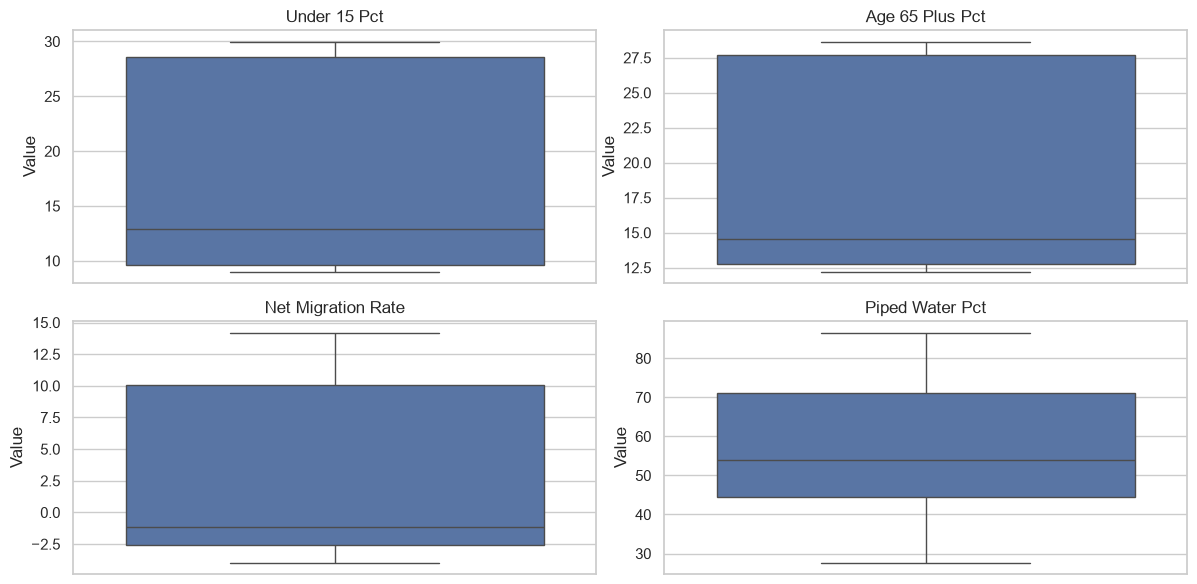

In [44]:
# ============================================================
# 9.2 OUTLIER ASSESSMENT USING BOXPLOTS
# ============================================================

plt.figure(figsize=(12, 6))

for i, feature in enumerate(feature_columns, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=analysis_data[feature])
    plt.title(feature.replace("_", " ").title())
    plt.ylabel("Value")

plt.tight_layout()
plt.show()

---

## 10. Feature Standardization

### 10.1 Standardizing the Clustering Variables

The four clustering variables have different measurement scales.
Standardization is therefore performed using the StandardScaler
method. Each feature is transformed to have a mean of approximately
zero and a standard deviation of approximately one.

The district identifier is excluded from the clustering process.
Standardized numerical features are used to ensure that each
indicator contributes comparably to the Euclidean distance
calculation.

In [45]:
# ============================================================
# 10.2 STANDARDIZE THE FOUR CLUSTERING FEATURES
# ============================================================

# Select only the numerical clustering features
X = analysis_data[feature_columns].copy()

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert standardized data into a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=feature_columns,
    index=analysis_data["district_id"]
)

# Display standardized values
display(X_scaled_df.round(3))

# Verify standardized means and standard deviations
print("\nStandardized feature means:")
display(X_scaled_df.mean().round(3))

print("\nStandardized feature standard deviations:")
display(X_scaled_df.std(ddof=0).round(3))

,under_15_pct,age_65_plus_pct,net_migration_rate,piped_water_pct
district_id,,,,
D01,1.429,-0.546,-0.777,-1.459
D02,-0.450,-0.872,1.048,1.428
D03,-0.922,1.413,-0.719,0.025
D04,1.266,-0.582,-0.921,-0.127
D05,-0.489,-0.871,1.709,1.246
D06,-0.894,1.447,-0.564,-0.339
D07,1.451,-0.552,-0.716,-0.685
D08,-0.501,-0.869,1.497,0.982
D09,-0.952,1.394,-0.587,-0.151



Standardized feature means:


under_15_pct          0.0
age_65_plus_pct      -0.0
net_migration_rate    0.0
piped_water_pct       0.0
dtype: float64


Standardized feature standard deviations:


under_15_pct          1.0
age_65_plus_pct       1.0
net_migration_rate    1.0
piped_water_pct       1.0
dtype: float64

---

## 11. K-Means Clustering

### 11.1 Determining the Number of Clusters: Elbow Method

K-means clustering is fitted for cluster sizes ranging from one
to six (k = 1 to 6). Each model is fitted using 50 initial
randomizations to reduce the likelihood of obtaining a poor
local solution.

The Within-Cluster Sum of Squares (WCSS), represented by the
model inertia, is recorded for each value of k. The elbow plot
is used to examine how the reduction in WCSS changes as the
number of clusters increases.

In [46]:
# ============================================================
# 11.2 FIT K-MEANS MODELS FOR k = 1 TO 6
# ============================================================

wcss = []
k_values = range(1, 7)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=RANDOM_STATE
    )

    model.fit(X_scaled)
    wcss.append(model.inertia_)

# Display WCSS results
wcss_results = pd.DataFrame({
    "k": list(k_values),
    "WCSS": wcss
})

display(wcss_results.round(4))

,k,WCSS
0,1,96.0000
1,2,44.9907
2,3,5.4710
3,4,3.4895
4,5,2.1883
5,6,1.3203


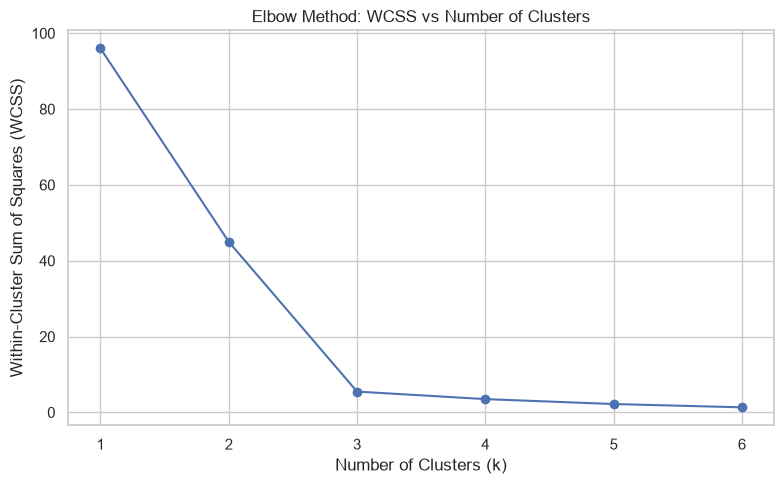

In [47]:
# ============================================================
# 11.3 ELBOW PLOT
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    wcss,
    marker="o"
)

plt.title("Elbow Method: WCSS vs Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

In [48]:
# ============================================================
# 11.4 PERCENTAGE REDUCTION IN WCSS
# ============================================================

wcss_reductions = []

for i in range(1, len(wcss)):
    reduction = ((wcss[i-1] - wcss[i]) / wcss[i-1]) * 100
    wcss_reductions.append(reduction)

reduction_table = pd.DataFrame({
    "From_k": list(range(1, 6)),
    "To_k": list(range(2, 7)),
    "WCSS_Reduction_Percent": wcss_reductions
})

display(reduction_table.round(2))

,From_k,To_k,WCSS_Reduction_Percent
0,1,2,53.13
1,2,3,87.84
2,3,4,36.22
3,4,5,37.29
4,5,6,39.66


---

## 12. Silhouette Analysis

The silhouette coefficient is used to evaluate the quality of
the clustering solutions. It measures how closely each district
is assigned to its own cluster compared with other clusters.

Mean silhouette scores are calculated for k = 2 to k = 6.
Higher scores indicate better separation and cohesion, although
the scores are interpreted alongside the elbow method and
demographic relevance.

In [49]:
# ============================================================
# 12.2 CALCULATE SILHOUETTE SCORES FOR k = 2 TO 6
# ============================================================

silhouette_results = []

from threadpoolctl import threadpool_limits

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=RANDOM_STATE
    )

    with threadpool_limits(limits=1):
        labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_results.append({
        "k": k,
        "Mean_Silhouette_Score": score
    })

silhouette_table = pd.DataFrame(silhouette_results)

display(silhouette_table.round(4))

,k,Mean_Silhouette_Score
0,2,0.5585
1,3,0.8168
2,4,0.7386
3,5,0.6294
4,6,0.6198


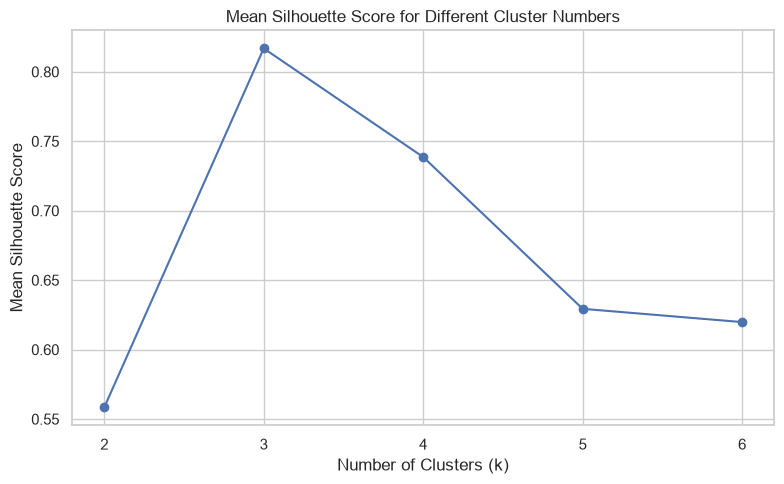

In [50]:
# ============================================================
# 12.3 SILHOUETTE SCORE COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    silhouette_table["k"],
    silhouette_table["Mean_Silhouette_Score"],
    marker="o"
)

plt.title("Mean Silhouette Score for Different Cluster Numbers")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Mean Silhouette Score")
plt.xticks(range(2, 7))
plt.tight_layout()
plt.show()

### 12.4 Individual Silhouette Plots

Individual silhouette plots are constructed for k = 3 and k = 4.
These plots allow the examination of cluster-level silhouette
values, cluster sizes, and the consistency of district assignments.

The two solutions are compared to assess the quality of cluster
separation and the presence of districts with weak or negative
silhouette coefficients.

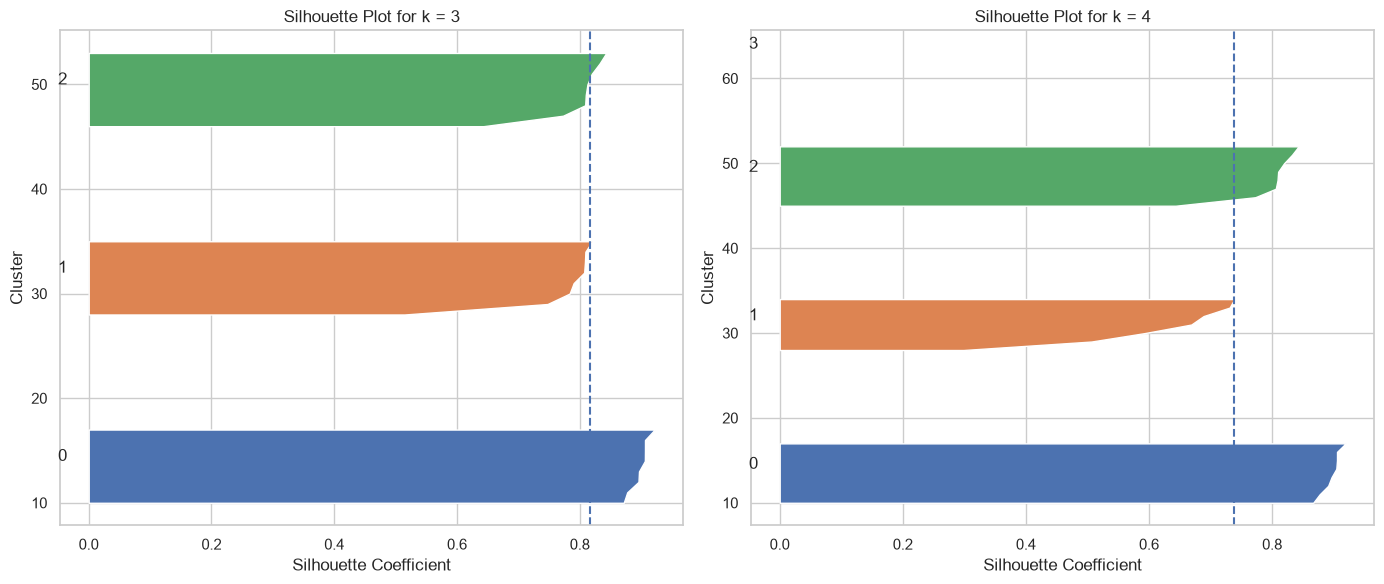

In [51]:
# ============================================================
# 12.5 INDIVIDUAL SILHOUETTE PLOTS FOR k = 3 AND k = 4
# ============================================================

from sklearn.metrics import silhouette_samples

candidate_ks = [3, 4]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, k in zip(axes, candidate_ks):

    model = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=RANDOM_STATE
    )

    with threadpool_limits(limits=1):
        labels = model.fit_predict(X_scaled)

    sample_silhouette_values = silhouette_samples(
        X_scaled,
        labels
    )

    average_silhouette = silhouette_score(
        X_scaled,
        labels
    )

    y_lower = 10

    for cluster in range(k):

        cluster_silhouette_values = sample_silhouette_values[
            labels == cluster
        ]

        cluster_silhouette_values.sort()

        cluster_size = len(cluster_silhouette_values)
        y_upper = y_lower + cluster_size

        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            cluster_silhouette_values
        )

        ax.text(
            -0.05,
            y_lower + cluster_size / 2,
            str(cluster)
        )

        y_lower = y_upper + 10

    ax.axvline(
        average_silhouette,
        linestyle="--"
    )

    ax.set_title(f"Silhouette Plot for k = {k}")
    ax.set_xlabel("Silhouette Coefficient")
    ax.set_ylabel("Cluster")

plt.tight_layout()
plt.show()

---

## 13. Final Clustering Solution

### 13.1 Fitting the Selected Three-Cluster Model

Based on the elbow method, mean silhouette scores, and individual
silhouette plots, three clusters are selected as the final
clustering solution.

The K-means model is fitted using k = 3, with 50 initializations
and a fixed random seed to ensure reproducibility. Cluster labels
are assigned to the 24 districts for subsequent analysis and
interpretation.

In [52]:
# ============================================================
# 13.2 FIT FINAL K-MEANS MODEL (k = 3)
# ============================================================

final_k = 3

final_model = KMeans(
    n_clusters=final_k,
    n_init=50,
    random_state=RANDOM_STATE
)

with threadpool_limits(limits=1):
    final_labels = final_model.fit_predict(X_scaled)

# Add cluster assignments to the analytical dataset
analysis_data["cluster"] = final_labels

# Display district assignments
cluster_assignments = analysis_data[
    ["district_id", "cluster"]
].sort_values("cluster")

display(cluster_assignments)

,district_id,cluster
2,D03,0
5,D06,0
11,D12,0
8,D09,0
14,D15,0
23,D24,0
20,D21,0
17,D18,0
13,D14,1
10,D11,1


In [53]:
# ============================================================
# 13.3 CLUSTER SIZE DISTRIBUTION
# ============================================================

cluster_sizes = (
    analysis_data["cluster"]
    .value_counts()
    .sort_index()
    .rename("District_Count")
    .to_frame()
)

cluster_sizes["Percentage"] = (
    cluster_sizes["District_Count"] / len(analysis_data) * 100
)

display(cluster_sizes.round(2))

,District_Count,Percentage
cluster,,
0,8,33.33
1,8,33.33
2,8,33.33


---

## 14. Cluster Interpretation

### 14.1 Cluster Centroids in Original Units

Cluster centroids are calculated using the original, unstandardized
features. This allows the demographic and socioeconomic characteristics
of each cluster to be interpreted in their original units.

The centroids are used to identify the distinguishing characteristics
of each district group.

In [54]:
# ============================================================
# 14.2 CALCULATE CLUSTER CENTROIDS IN ORIGINAL UNITS
# ============================================================

cluster_centroids = (
    analysis_data.groupby("cluster")[feature_columns]
    .mean()
)

display(cluster_centroids.round(2))

,under_15_pct,age_65_plus_pct,net_migration_rate,piped_water_pct
cluster,,,,
0,9.49,27.89,-1.53,53.79
1,12.90,12.56,12.01,75.97
2,28.97,14.59,-2.77,38.75


In [55]:
# ============================================================
# 14.3 DISPLAY CLUSTER CHARACTERISTICS
# ============================================================

cluster_summary = cluster_centroids.copy()

cluster_summary.index = [
    f"Cluster {i}" for i in cluster_summary.index
]

display(cluster_summary.round(2))

,under_15_pct,age_65_plus_pct,net_migration_rate,piped_water_pct
Cluster 0,9.49,27.89,-1.53,53.79
Cluster 1,12.90,12.56,12.01,75.97
Cluster 2,28.97,14.59,-2.77,38.75


### 14.4 Interpretation of Cluster Profiles

**Cluster 0: Older-Population Districts**

Cluster 0 is characterised by a relatively older population structure. The average proportion of individuals aged 65 and above is 27.89%, which is the highest among the three clusters, while the proportion of individuals under 15 years is relatively low at 9.49%. The cluster also exhibits a slightly negative net migration rate of -1.53 per 1,000 population. Piped-water access averages 53.79%. These characteristics suggest that Cluster 0 consists of districts with relatively ageing populations and a low proportion of children.

**Cluster 1: Migration-Attracting Districts**

Cluster 1 is characterised by positive net migration, with an average net migration rate of 12.01 per 1,000 population. It also has the highest average piped-water access at 75.97%. The proportion of individuals under 15 years is 12.90%, while the proportion aged 65 and above is 12.56%. These findings suggest that the districts in this cluster are experiencing relatively strong net population inflows and have comparatively higher access to piped water.

**Cluster 2: Younger-Population Districts**

Cluster 2 is characterised by a relatively high proportion of individuals under 15 years, averaging 28.97%, which is the highest among the three clusters. The proportion aged 65 and above is 14.59%. The cluster has the lowest average piped-water access at 38.75% and a negative net migration rate of -2.77 per 1,000 population. These characteristics suggest that the districts in Cluster 2 have relatively young populations and lower piped-water access compared with the other clusters.

**Overall Interpretation**

The three-cluster solution identifies distinct district profiles based on age structure, net migration and piped-water access. Cluster 0 represents relatively older-population districts, Cluster 1 represents districts characterised by positive net migration and higher piped-water access, while Cluster 2 represents younger-population districts with comparatively lower piped-water access. The resulting clusters provide a basis for comparing demographic and socioeconomic characteristics across districts.

---

## 15. Visualisation of Cluster Profiles

### 15.1 Cluster Centroid Heatmap

A heatmap is constructed to visualise the differences between
cluster centroids. The centroids are standardised for visual
comparison across variables, while the original-unit centroid
values remain the basis for demographic interpretation.

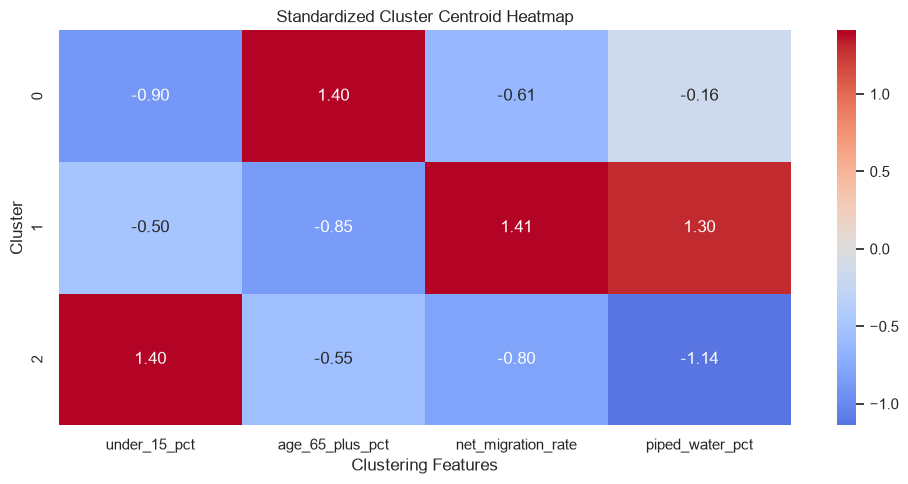

In [56]:
# ============================================================
# 15.2 CLUSTER CENTROID HEATMAP
# ============================================================

# Standardize cluster centroid values for visual comparison
centroid_scaler = StandardScaler()

centroids_scaled = centroid_scaler.fit_transform(
    cluster_centroids
)

centroids_scaled_df = pd.DataFrame(
    centroids_scaled,
    index=cluster_centroids.index,
    columns=feature_columns
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    centroids_scaled_df,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Standardized Cluster Centroid Heatmap")
plt.xlabel("Clustering Features")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

### 15.3 Interpretation of the Cluster Centroid Heatmap

The standardized centroid heatmap visually illustrates the distinguishing characteristics of the three clusters across the four clustering variables.

Cluster 0 exhibits a substantially higher standardized value for the proportion of individuals aged 65 and above, while the proportion of individuals under 15 is relatively low. This pattern reinforces the interpretation of Cluster 0 as representing districts with relatively ageing populations.

Cluster 1 exhibits high standardized values for net migration rate and piped-water access. These characteristics distinguish this cluster from the other two clusters and suggest that its districts experience relatively strong net population inflows and comparatively higher access to piped water.

Cluster 2 exhibits a substantially higher standardized value for the proportion of individuals under 15 and a lower standardized value for piped-water access. This pattern reinforces the interpretation of Cluster 2 as representing relatively younger-population districts with comparatively lower access to piped water.

Overall, the heatmap provides a visual comparison of the cluster profiles and supports the demographic interpretation obtained from the original-unit cluster centroids.

---

## 16. Clustering Stability Analysis

The stability of the selected clustering solution is assessed
under alternative modelling conditions.

First, the K-means model is fitted using an alternative random
seed while maintaining the same features and imputation method.
Second, mean imputation is applied to the missing piped-water
values as an alternative to median imputation.

The Adjusted Rand Index (ARI) is used to compare the alternative
cluster assignments with the original three-cluster solution.
The ARI measures the agreement between clustering partitions,
with values closer to one indicating stronger agreement.

In [57]:
# ============================================================
# 16.2 STABILITY TEST: ALTERNATIVE RANDOM SEED
# ============================================================

# Fit K-means using an alternative random seed
alternative_seed_model = KMeans(
    n_clusters=3,
    n_init=50,
    random_state=123
)

with threadpool_limits(limits=1):
    alternative_seed_labels = alternative_seed_model.fit_predict(X_scaled)

# Compare the original clustering with the alternative seed
ari_seed = adjusted_rand_score(
    final_labels,
    alternative_seed_labels
)

print("ARI - Alternative Random Seed:", round(ari_seed, 4))

ARI - Alternative Random Seed: 1.0


### 16.3 Interpretation of Alternative Random Seed Stability

The K-means model was refitted using an alternative random seed of 123 while maintaining the same three-cluster specification, features and imputation method. The Adjusted Rand Index (ARI) between the original and alternative clustering solutions was 1.0000.

An ARI value of 1.0000 indicates perfect agreement between the two clustering partitions. All districts retained their corresponding cluster memberships under the alternative random seed. This suggests that the selected three-cluster solution is highly stable with respect to random seed variation and is not dependent on a particular random initialization.

In [58]:
# ============================================================
# 16.4 STABILITY TEST: ALTERNATIVE IMPUTATION (MEAN)
# ============================================================

# Reconstruct the original feature dataset before imputation
mean_imputed_data = age_features.merge(
    migration_features,
    on="district_id",
    how="inner"
).merge(
    water_features,
    on="district_id",
    how="inner"
)

# Replace missing water values using the mean
water_mean = mean_imputed_data["piped_water_pct"].mean()

mean_imputed_data["piped_water_pct"] = (
    mean_imputed_data["piped_water_pct"].fillna(water_mean)
)

print("Mean used for imputation:", round(water_mean, 4))

# Extract the four features
X_mean = mean_imputed_data[feature_columns]

# Standardize the mean-imputed dataset
scaler_mean = StandardScaler()
X_mean_scaled = scaler_mean.fit_transform(X_mean)

# Fit K-means with the same k and random seed
mean_imputation_model = KMeans(
    n_clusters=3,
    n_init=50,
    random_state=42
)

with threadpool_limits(limits=1):
    mean_imputation_labels = mean_imputation_model.fit_predict(
        X_mean_scaled
    )

# Compare with the original median-imputation solution
ari_imputation = adjusted_rand_score(
    final_labels,
    mean_imputation_labels
)

print("ARI - Alternative Imputation:", round(ari_imputation, 4))

Mean used for imputation: 56.3682
ARI - Alternative Imputation: 1.0


### 16.5 Interpretation of Clustering Stability

The stability of the selected three-cluster solution was assessed using two sensitivity tests. First, the K-means model was refitted using an alternative random seed of 123. The resulting Adjusted Rand Index (ARI) was 1.0000, indicating perfect agreement with the original clustering solution.

Second, mean imputation was used as an alternative to median imputation for the two missing piped-water observations. The mean imputation value was 56.3682%. The resulting clustering solution also produced an ARI of 1.0000 compared with the original median-imputation solution.

Both sensitivity tests demonstrate perfect agreement with the original cluster memberships. These findings indicate that the three-cluster solution is robust to the tested changes in random seed and imputation method. However, this stability is limited to the specific sensitivity tests conducted and does not establish robustness to all possible modelling choices.

---

## 17. Limitations and Practical Application

### 17.1 Practical Application of the Clustering

The district clusters can support evidence-based planning and
resource allocation. Districts in Cluster 2, characterised by
a relatively high proportion of children under 15 and lower
piped-water access, could be prioritised for planning of
child-related services and improvements in water infrastructure.

The clusters can also help policymakers compare districts
with similar demographic characteristics and develop
interventions tailored to their population profiles.

### 17.2 Limitation of the Clustering

One limitation of the analysis is that clustering is based on
only four indicators. Other factors such as income, education,
healthcare access, employment, infrastructure and urbanisation
may influence district characteristics but are not included.

Furthermore, K-means assigns districts to clusters based on
similarity in the selected variables, and the resulting groups
do not necessarily represent all underlying differences
between districts. Therefore, the clusters should be used as
a planning and exploratory tool rather than as a definitive
classification of districts.

---

## 18. Final Results Summary and Conclusion

### 18.1 Summary of the Analysis

The analysis used K-means clustering to classify 24 districts into groups based on four demographic and socioeconomic indicators: the percentage of the population under 15 years, the percentage aged 65 and above, the net migration rate per 1,000 population, and piped-water access.

Missing values in piped-water access were handled using median imputation. Outlier assessment was conducted using boxplots, and the four features were standardised before clustering. The Elbow Method and Silhouette Analysis were used to evaluate the appropriate number of clusters.

Based on these diagnostics, **three clusters (k = 3)** were selected. The model produced three distinct district profiles:

- **Cluster 0 – Older-population districts:** Characterised by a relatively high proportion of people aged 65 and above and a low proportion of children under 15.
- **Cluster 1 – Migration-attracting districts:** Characterised by positive net migration and comparatively higher piped-water access.
- **Cluster 2 – Younger-population districts:** Characterised by a high proportion of children under 15 and comparatively lower piped-water access.

The selected three-cluster model achieved a mean silhouette score of 0.8168, indicating strong separation between the resulting clusters.

### 18.2 Model Stability

The clustering solution was tested using an alternative random seed and an alternative imputation method. Both tests produced an Adjusted Rand Index (ARI) of 1.0000 when compared with the original clustering solution.

This indicates that the district assignments remained unchanged under the two tested variations, suggesting that the clustering solution was stable under these conditions.

### 18.3 Conclusion

The K-means clustering analysis successfully grouped the 24 districts into three distinct profiles based on demographic structure, migration patterns and piped-water access. The findings demonstrate how clustering techniques can be used to identify similarities between districts and support evidence-based planning.

The resulting clusters can help policymakers identify areas with different population needs and tailor interventions accordingly. However, the clusters should be interpreted as exploratory analytical groupings rather than definitive classifications of districts.
